Variância retida pelo PCA: 78.74%
(Isso indica o quanto da 'verdade' matemática das 4 dimensões sobreviveu no gráfico 2D)

Silhouette Score: 0.246
(Valores mais altos indicam clusters bem separados e coesos)

PERFIL MATEMÁTICO DOS CLUSTERS (Média de 0 a 1):
         energy_rms_norm  tempo_bpm_norm  spectral_centroid_norm  zcr_norm
cluster                                                                   
0                  0.199           0.529                   0.196     0.117
1                  0.233           0.408                   0.433     0.265
2                  0.481           0.407                   0.297     0.141
3                  0.184           0.329                   0.172     0.109

Distribuição das tags originais dentro de cada Cluster:
mood_label  Dark  Happy  Sad
cluster                     
0            171    122  210
1            187    228  102
2            169    280  126
3            273    170  362


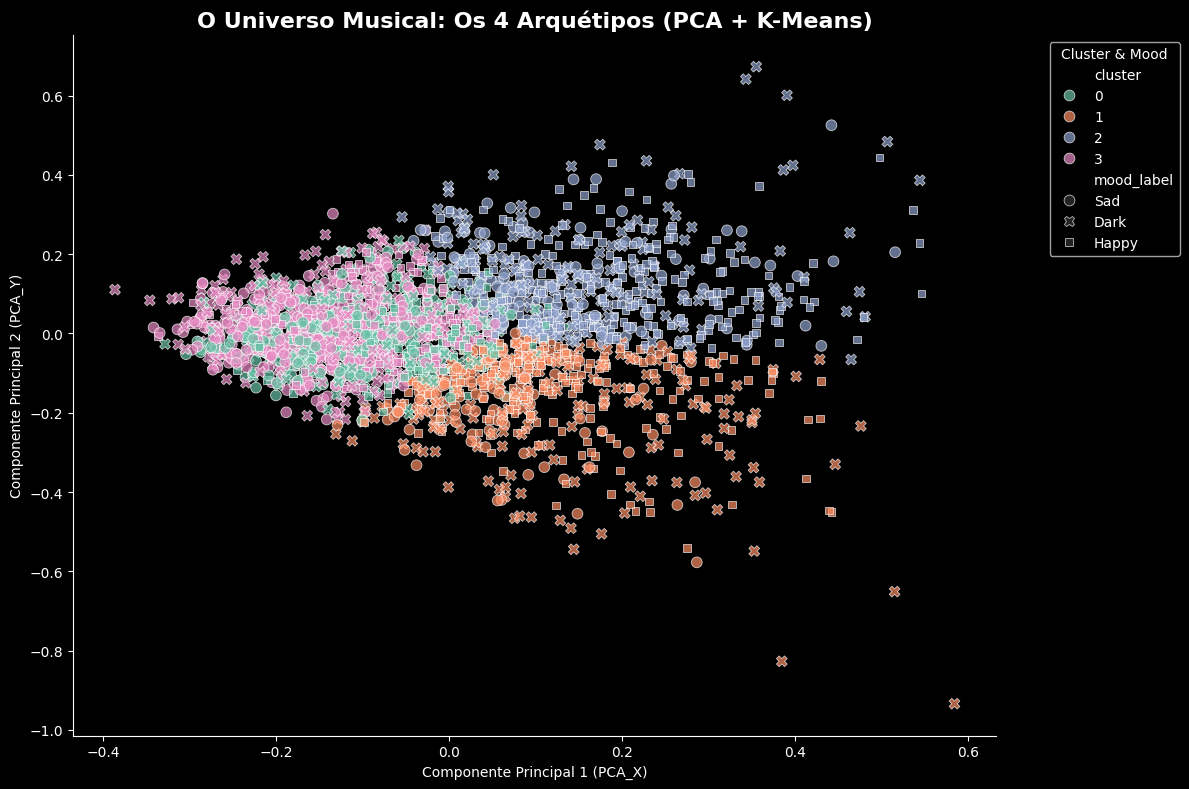

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configuração visual
plt.style.use('dark_background')

# 1. Carregar Dados e Preparar Features
df = pd.read_parquet("../data/processed/analytical_base_table.parquet")

# Recriar a label de mood para visualização (caso não tenha sido salva na ABT)
def assign_mood(row):
    if row['is_sad']: return 'Sad'
    if row['is_happy']: return 'Happy'
    if row['is_dark']: return 'Dark'
    return 'Unknown'

if 'mood_label' not in df.columns:
    df['mood_label'] = df.apply(assign_mood, axis=1)

features = ["energy_rms_norm", "tempo_bpm_norm", "spectral_centroid_norm", "zcr_norm"]
X = df[features]

# 2. PCA (Redução Dimensional de 4D para 2D)
pca = PCA(n_components=2, random_state=42)
pca_coords = pca.fit_transform(X)
df['pca_x'] = pca_coords[:, 0]
df['pca_y'] = pca_coords[:, 1]

print(f"Variância retida pelo PCA: {pca.explained_variance_ratio_.sum():.2%}")
print("(Isso indica o quanto da 'verdade' matemática das 4 dimensões sobreviveu no gráfico 2D)\n")

# 3. Clusterização (Descobrindo os Arquétipos)
# Testando 4 agrupamentos como ponto de partida para a narrativa
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

# 4. Avaliação Estatística
score = silhouette_score(X, df['cluster'])
print(f"Silhouette Score: {score:.3f}")
print("(Valores mais altos indicam clusters bem separados e coesos)\n")

# 5. O Raio-X de cada Cluster
cluster_profiles = df.groupby('cluster')[features].mean()
print("PERFIL MATEMÁTICO DOS CLUSTERS (Média de 0 a 1):")
print(cluster_profiles.round(3))
print("\nDistribuição das tags originais dentro de cada Cluster:")
print(pd.crosstab(df['cluster'], df['mood_label']))

# 6. Visualizar o "Musical Universe"
plt.figure(figsize=(12, 8))
sns.scatterplot(
    data=df, 
    x='pca_x', 
    y='pca_y', 
    hue='cluster', 
    palette='Set2', 
    style='mood_label',
    alpha=0.7, 
    s=60
)
plt.title("O Universo Musical: Os 4 Arquétipos (PCA + K-Means)", fontsize=16, fontweight='bold')
plt.xlabel("Componente Principal 1 (PCA_X)")
plt.ylabel("Componente Principal 2 (PCA_Y)")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', title="Cluster & Mood")
sns.despine()
plt.tight_layout()
plt.show()

# 7. Salvar base processada para o Frontend (React/D3)
df.to_parquet("../data/processed/clustered_universe.parquet", index=False)

In [2]:
import pandas as pd

df = pd.read_parquet("../data/processed/clustered_universe.parquet")

print("--- A Falsa Felicidade (Sad songs in Acoustic Nostalgia) ---")
falsa_felicidade = df[(df['mood_label'] == 'Sad') & (df['cluster'] == 1)]
print(falsa_felicidade[['track_id', 'energy_rms_norm', 'tempo_bpm_norm']].head(3))

print("\n--- O Desespero Barulhento (Sad songs in Dense Intensity) ---")
desespero = df[(df['mood_label'] == 'Sad') & (df['cluster'] == 2)]
print(desespero[['track_id', 'energy_rms_norm', 'tempo_bpm_norm']].head(3))

--- A Falsa Felicidade (Sad songs in Acoustic Nostalgia) ---
         track_id  energy_rms_norm  tempo_bpm_norm
6   track_0016661         0.170890        0.500000
18  track_0025271         0.316686        0.360000
64  track_0047404         0.231155        0.391304

--- O Desespero Barulhento (Sad songs in Dense Intensity) ---
         track_id  energy_rms_norm  tempo_bpm_norm
8   track_0021983         0.377426        0.310345
34  track_0036657         0.510459        0.529412
61  track_0045570         0.386246        0.333333


In [4]:
import json, pandas as pd
df = pd.read_parquet("../data/processed/clustered_universe.parquet")
ids = json.load(open("../web/public/data/audio_ids.json"))
cr = json.load(open("../web/public/data/credits.json"))
cols = ["track_id", "cluster", "energy_rms_norm", "tempo_bpm_norm",
        "spectral_centroid_norm", "zcr_norm"]
out = df[df.track_id.isin(ids)][cols].copy()
out["title"] = out.track_id.map(lambda t: cr[t]["title"])
print(out.sort_values("cluster").round(2).to_string(index=False))

     track_id  cluster  energy_rms_norm  tempo_bpm_norm  spectral_centroid_norm  zcr_norm                           title
track_0426030        1             0.42            0.35                    0.50      0.26                 This Is For You
track_0944979        1             0.17            0.39                    0.64      0.50                    Dernier jour
track_1150508        1             0.11            0.47                    0.56      0.27                       Slid down
track_1167871        1             0.21            0.45                    0.59      0.31                          Recall
track_1300500        1             0.03            0.45                    0.53      0.37                 Endless Journey
track_1203194        1             0.23            0.53                    0.49      0.33                       Hold Fast
track_1096788        2             0.64            0.43                    0.12      0.04 The Descenters - All is Nothing
track_0476791        2  

In [2]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

df = pd.read_parquet("../data/processed/clustered_universe.parquet")
X = df[["energy_rms_norm", "tempo_bpm_norm", "spectral_centroid_norm", "zcr_norm"]]

for k in range(2, 9):
    lab = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)
    print(k, round(silhouette_score(X, lab), 3))

2 0.299
3 0.297
4 0.246
5 0.245
6 0.247
7 0.242
8 0.241
